In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from MNIST1DPoissonTarget import SpikingMNIST1D

def visualize_spiking_mnist1d(dataset, index=0):
    """
    Visualizes a single sample from the SpikingMNIST1D dataset.
    
    Creates a 3-panel figure:
    1. Raster plot of the input spike trains.
    2. The reconstructed 1D waveform based on empirical firing rates.
    3. Raster plot of the target spike trains.
    """
    # 1. Fetch the data
    x_spikes, y_spikes, label, targets, target_fr = dataset[index]
    T = x_spikes.shape[0]
    num_features = x_spikes.shape[1]
    
    fig = plt.figure(figsize=(10, 10))
    
    # ---------------------------------------------------------
    # Panel 1: Input Spike Raster Plot
    # ---------------------------------------------------------
    ax1 = fig.add_subplot(311)
    # Get time indices and neuron indices where spikes occur (value > 0)
    times_x, neurons_x = np.where(x_spikes > 0)
    
    ax1.scatter(times_x, neurons_x, s=4, c='black', marker='|')
    ax1.set_title(f"Input Spike Trains (True Digit: {int(label)})", fontsize=14, fontweight='bold')
    ax1.set_ylabel("Input Feature Index (0-39)")
    ax1.set_xlim(0, T)
    ax1.set_ylim(-1, num_features)
    ax1.grid(True, axis='y', linestyle='--', alpha=0.3)
    
    # ---------------------------------------------------------
    # Panel 2: Reconstructed 1D Waveform (Firing Rate Profile)
    # ---------------------------------------------------------
    ax2 = fig.add_subplot(312)
    # Calculate empirical firing rate (Hz) per feature: (Spikes / T_ms) * 1000
    empirical_fr = x_spikes.sum(axis=0) * (1000 / T)
    
    ax2.plot(range(num_features), empirical_fr, marker='o', color='tab:blue', linewidth=2)
    ax2.fill_between(range(num_features), empirical_fr, alpha=0.2, color='tab:blue')
    ax2.set_title("Reconstructed MNIST1D Waveform (Derived from Firing Rates)", fontsize=12)
    ax2.set_ylabel("Firing Rate (Hz)")
    ax2.set_xlabel("Input Feature Index (Spatial dimension)")
    ax2.set_xlim(0, num_features - 1)
    ax2.grid(True, linestyle='--', alpha=0.6)
    
    # ---------------------------------------------------------
    # Panel 3: Target Spike Raster Plot
    # ---------------------------------------------------------
    ax3 = fig.add_subplot(313)
    times_y, neurons_y = np.where(y_spikes > 0)
    
    ax3.scatter(times_y, neurons_y, s=30, c='tab:red', marker='|')
    # Highlight the row corresponding to the correct label
    ax3.axhspan(label - 0.5, label + 0.5, color='gold', alpha=0.2, label='Target Class')
    
    ax3.set_title(f"Target Output Spikes (High FR for class {int(label)})", fontsize=12)
    ax3.set_ylabel("Class Index (0-9)")
    ax3.set_xlabel("Time (ms)")
    ax3.set_xlim(0, T)
    ax3.set_ylim(-0.5, 9.5)
    ax3.set_yticks(range(10))
    ax3.legend(loc='upper right')
    
    plt.tight_layout()
    plt.show()

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from MNIST1DPoissonTarget import SpikingMNIST1D


# 1. Define the target firing rates [target_high, target_low]
# Example: The correct class fires at 80 Hz, incorrect classes fire at 5 Hz
target_firing_rates = np.array([80.0, 5.0]) 

# 2. Instantiate your dataset
# (Ensure the mnist1d scripts are in your working directory/Python path)
spiking_dataset = SpikingMNIST1D(
    target_fr=target_firing_rates,
    size=100,               # Generate 100 samples
    seed=42,
    T=1000,                 # 1000 ms simulation time
    fmin=10,                # Minimum input frequency
    fmax=100,               # Maximum input frequency
    homogeneous_poisson=True, # Use deterministic inhomogeneous Poisson
    regular=False
)

# 3. Visualize a sample (e.g., the first sample at index 0)
# visualize_spiking_mnist1d(spiking_dataset, index=0)

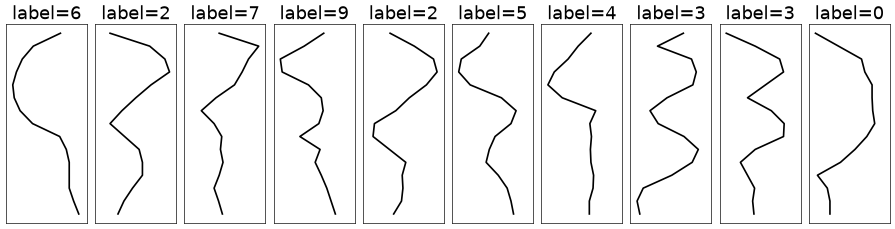

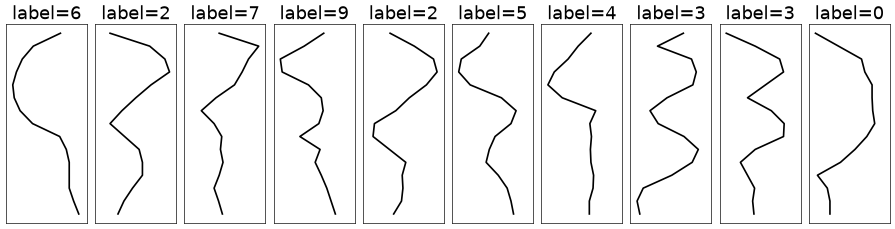

In [45]:
import matplotlib.pyplot as plt
import numpy as np

def plot_reconstructed_signals(dataset, num_samples=10, ratio=2.6, dark_mode=False):
    """
    Plots the reconstructed 1D waveform (empirical firing rate) of the SpikingMNIST1D
    dataset in the same style as the original MNIST1D plot_signals function.
    """
    rows = 1
    cols = min(num_samples, 10)
    
    fig = plt.figure(figsize=[cols*1.5, rows*1.5*ratio], dpi=60)
    
    for ix in range(rows * cols):
        # 1. Fetch the data from the dataset
        x_spikes, y_spikes, label, targets, target_fr = dataset[ix]
        T = x_spikes.shape[0]
        
        # 2. Reconstruct the 1D waveform (empirical firing rate)
        # Calculate empirical firing rate (Hz) per feature: (Spikes / T_ms) * 1000
        empirical_fr = x_spikes.sum(axis=0) * (1000 / T)
        
        # The spatial dimension 't' (0 to 39)
        t_spatial = np.arange(len(empirical_fr))
        
        # Normalize the signal slightly so it fits nicely in the vertical plots if needed
        # (The original plot_signals expects signals roughly centered around 0 for zoom limits)
        x_signal = empirical_fr - np.mean(empirical_fr)
        
        # 3. Plotting in the original format
        ax = plt.subplot(rows, cols, ix + 1)
        
        if dark_mode:
            # plt.plot(x, y): original plots signal on X-axis, spatial dimension on Y-axis
            plt.plot(x_signal, t_spatial, 'wo', linewidth=6)
            ax.set_facecolor('k')
        else:
            plt.plot(x_signal, t_spatial, 'k-', linewidth=2)
            
        plt.title("label=" + str(int(label)), fontsize=22)

        # Optional: Set a fixed x-limit so all digits share the same scale
        zoom = np.max(np.abs(x_signal)) * 1.2
        if zoom > 0:
            plt.xlim(-zoom, zoom)
            
        # Invert Y-axis so index 0 is at the top (like an image)
        plt.gca().invert_yaxis() 
        plt.xticks([], [])
        plt.yticks([], [])
        
    plt.subplots_adjust(wspace=0, hspace=0)
    plt.tight_layout()
    plt.show()
    return fig

plot_reconstructed_signals(spiking_dataset, num_samples=10, dark_mode=False)


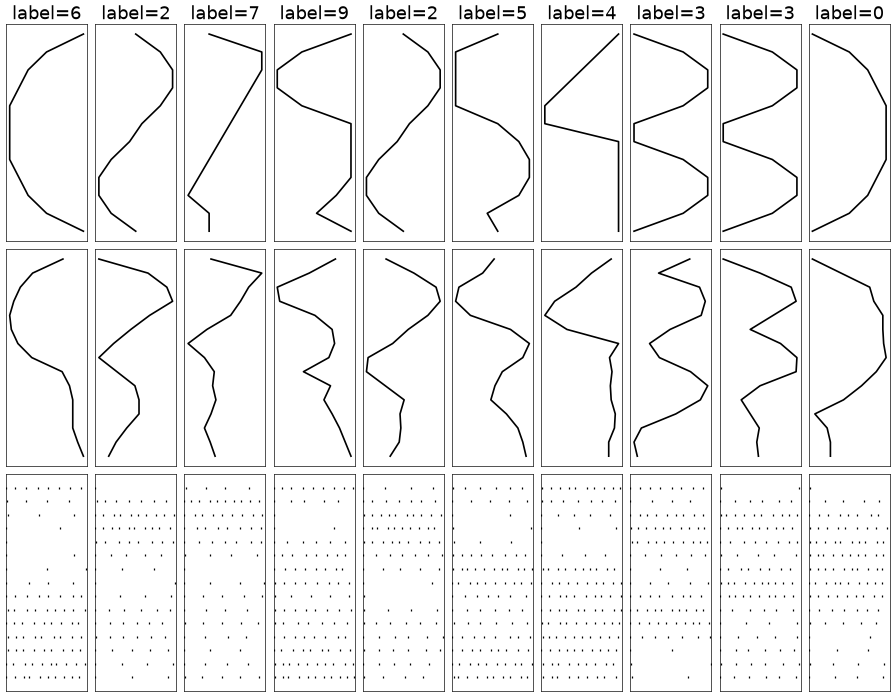

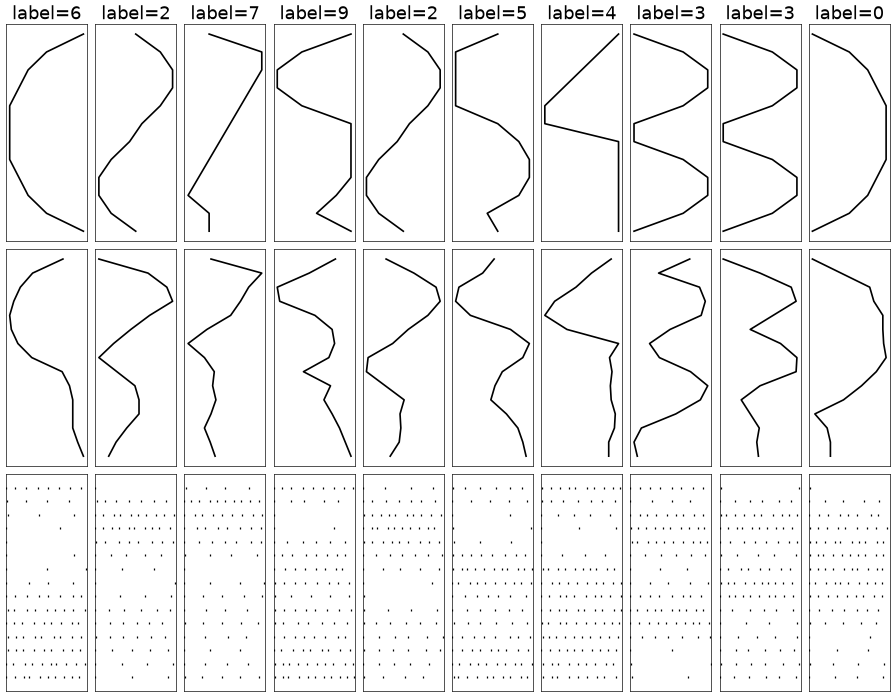

In [46]:
import matplotlib.pyplot as plt
import numpy as np
from MNIST1DPoissonTarget import get_templates

def plot_mnist1d_comparison(dataset, num_samples=10, ratio=2.6, snippet_T=100, dark_mode=False):
    """
    Plots a 3-row grid for the MNIST1D dataset:
    Row 1: Clean template (no noise/padding)
    Row 2: Transformed pattern (with noise/padding, before spike encoding)
    Row 3: Snippet of the corresponding raster plot
    """
    rows = 3
    cols = min(num_samples, 10)
    
    fig = plt.figure(figsize=[cols*1.5, rows*1.5*ratio], dpi=60)
    templates = get_templates()
    
    for ix in range(cols):
        # 1. Fetch data
        x_spikes, _, label, _, _ = dataset[ix]
        label_int = int(label)
        
        # Check if we have raw_x stored (it should be since I updated the file)
        if hasattr(dataset, 'raw_x'):
            transformed_x = dataset.raw_x[ix]
        else:
            # Fallback just in case you haven't re-instantiated the dataset
            T = x_spikes.shape[0]
            transformed_x = x_spikes.sum(axis=0) * (1000 / T)
            
        num_features = len(transformed_x) # 40
        
        # ==========================================
        # ROW 1: Clean Template (Length 12)
        # ==========================================
        ax1 = plt.subplot(rows, cols, ix + 1)
        clean_x = templates['x'][label_int]
        t_clean = np.arange(len(clean_x))
        
        clean_x = clean_x - np.mean(clean_x) # Center signal
        
        if dark_mode:
            plt.plot(clean_x, t_clean, 'wo', linewidth=6)
            ax1.set_facecolor('k')
        else:
            plt.plot(clean_x, t_clean, 'k-', linewidth=2)
            
        plt.title(f"label={label_int}", fontsize=22)
        plt.gca().invert_yaxis()
        plt.xticks([], [])
        plt.yticks([], [])
        
        # ==========================================
        # ROW 2: Transformed Pattern (Length 40)
        # ==========================================
        ax2 = plt.subplot(rows, cols, cols + ix + 1)
        t_spatial = np.arange(num_features)
        
        transformed_x = transformed_x - np.mean(transformed_x) # Center signal
        
        if dark_mode:
            plt.plot(transformed_x, t_spatial, 'wo', linewidth=6)
            ax2.set_facecolor('k')
        else:
            plt.plot(transformed_x, t_spatial, 'k-', linewidth=2)
            
        plt.gca().invert_yaxis()
        plt.xticks([], [])
        plt.yticks([], [])
        
        # ==========================================
        # ROW 3: Raster Plot Snippet
        # ==========================================
        ax3 = plt.subplot(rows, cols, 2*cols + ix + 1)
        
        # Extract snippet of first snippet_T ms
        snippet = x_spikes[:snippet_T, :]
        times, neurons = np.where(snippet > 0)
        
        # Plot Time on X-axis, Neurons on Y-axis (so it aligns with Row 2)
        if dark_mode:
            plt.scatter(times, neurons, s=8, c='white', marker='|')
            ax3.set_facecolor('k')
        else:
            plt.scatter(times, neurons, s=8, c='black', marker='|')
            
        plt.xlim(0, snippet_T)
        plt.ylim(-1, num_features)
        
        # Invert Y-axis so neuron 0 is at the top, matching Row 2 exactly
        plt.gca().invert_yaxis() 
        plt.xticks([], [])
        plt.yticks([], [])
        
    plt.subplots_adjust(wspace=0, hspace=0)
    plt.tight_layout()
    plt.show()
    return fig

plot_mnist1d_comparison(spiking_dataset, num_samples=10, snippet_T=100)


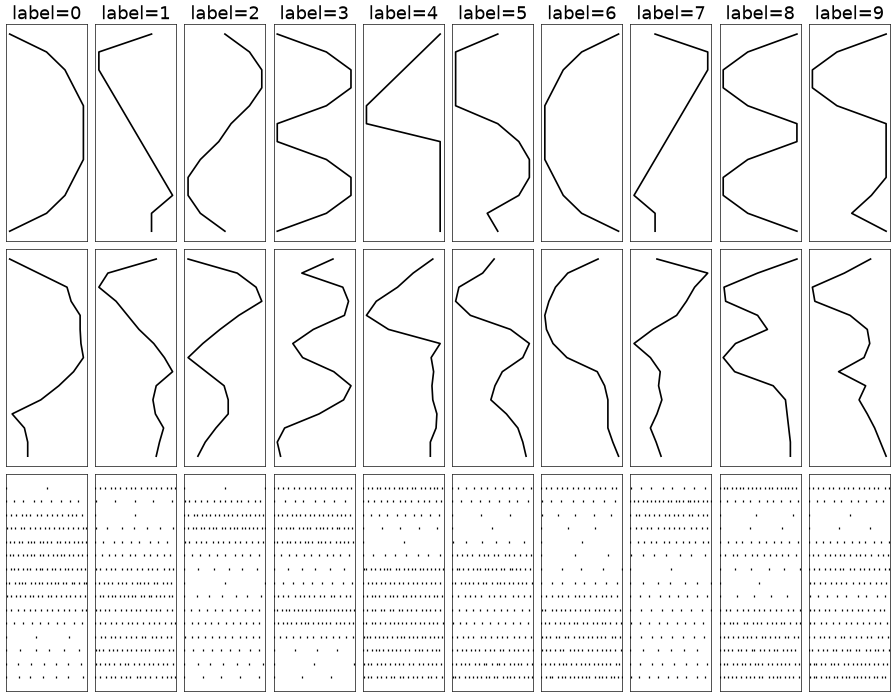

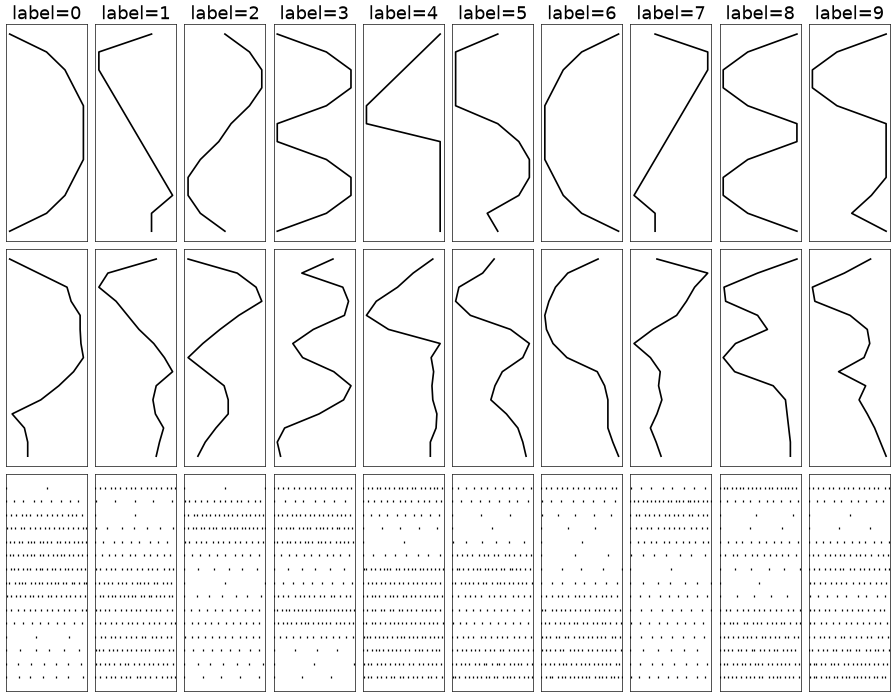

In [47]:
import matplotlib.pyplot as plt
import numpy as np
from MNIST1DPoissonTarget import get_templates

def plot_mnist1d_comparison(dataset, ratio=2.6, snippet_T=1000, dark_mode=False):
    """
    Plots a 3-row grid for the MNIST1D dataset, showing digits 0-9 in order:
    Row 1: Clean template (no noise/padding)
    Row 2: Transformed pattern (with noise/padding, before spike encoding)
    Row 3: Snippet of the corresponding raster plot
    """
    rows = 3
    cols = 10 # We want exactly one of each digit (0 to 9)
    
    fig = plt.figure(figsize=[cols*1.5, rows*1.5*ratio], dpi=60)
    templates = get_templates()
    
    # Find the first index in the dataset for each digit 0 through 9
    digit_indices = []
    labels_array = np.array(dataset.labels)
    for digit in range(10):
        # Find all indices matching the digit, and just take the very first one
        idx = np.where(labels_array == digit)[0][0]
        digit_indices.append(idx)
    
    # Loop over the 10 specific indices we found
    for plot_col, ix in enumerate(digit_indices):
        # 1. Fetch data
        x_spikes, _, label, _, _ = dataset[ix]
        label_int = int(label) # This will match plot_col (0 to 9)
        
        # Check if we have raw_x stored
        if hasattr(dataset, 'raw_x'):
            transformed_x = dataset.raw_x[ix]
        else:
            T = x_spikes.shape[0]
            transformed_x = x_spikes.sum(axis=0) * (1000 / T)
            
        num_features = len(transformed_x) # 40
        
        # ==========================================
        # ROW 1: Clean Template (Length 12)
        # ==========================================
        ax1 = plt.subplot(rows, cols, plot_col + 1)
        clean_x = templates['x'][label_int]
        t_clean = np.arange(len(clean_x))
        
        clean_x = clean_x - np.mean(clean_x) # Center signal
        
        if dark_mode:
            plt.plot(clean_x, t_clean, 'wo', linewidth=6)
            ax1.set_facecolor('k')
        else:
            plt.plot(clean_x, t_clean, 'k-', linewidth=2)
            
        plt.title(f"label={label_int}", fontsize=22)
        plt.gca().invert_yaxis()
        plt.xticks([], [])
        plt.yticks([], [])
        
        # ==========================================
        # ROW 2: Transformed Pattern (Length 40)
        # ==========================================
        ax2 = plt.subplot(rows, cols, cols + plot_col + 1)
        t_spatial = np.arange(num_features)
        
        transformed_x = transformed_x - np.mean(transformed_x) # Center signal
        
        if dark_mode:
            plt.plot(transformed_x, t_spatial, 'wo', linewidth=6)
            ax2.set_facecolor('k')
        else:
            plt.plot(transformed_x, t_spatial, 'k-', linewidth=2)
            
        plt.gca().invert_yaxis()
        plt.xticks([], [])
        plt.yticks([], [])
        
        # ==========================================
        # ROW 3: Raster Plot Snippet
        # ==========================================
        ax3 = plt.subplot(rows, cols, 2*cols + plot_col + 1)
        
        # Extract snippet of first snippet_T ms
        snippet = x_spikes[:snippet_T, :]
        times, neurons = np.where(snippet > 0)
        
        # Plot Time on X-axis, Neurons on Y-axis (so it aligns with Row 2)
        if dark_mode:
            plt.scatter(times, neurons, s=8, c='white', marker='|')
            ax3.set_facecolor('k')
        else:
            plt.scatter(times, neurons, s=8, c='black', marker='|')
            
        plt.xlim(0, snippet_T)
        plt.ylim(-1, num_features)
        
        # Invert Y-axis so neuron 0 is at the top, matching Row 2 exactly
        plt.gca().invert_yaxis() 
        plt.xticks([], [])
        plt.yticks([], [])
        
    plt.subplots_adjust(wspace=0, hspace=0)
    plt.tight_layout()
    plt.show()
    return fig

# --- Usage Example ---
plot_mnist1d_comparison(spiking_dataset, snippet_T=200, dark_mode=False)


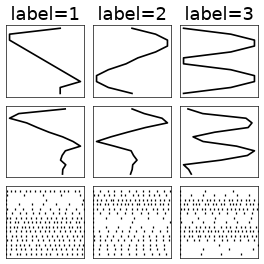

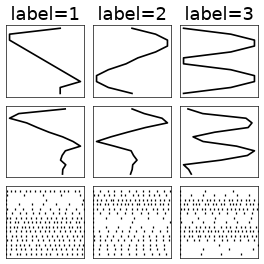

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from MNIST1DPoissonTarget import get_templates

def plot_mnist1d_comparison(dataset, digits_to_plot=None, ratio=1.0, snippet_T=1000, dark_mode=False):
    """
    Plots a 3-row grid for the MNIST1D dataset, showing specified digits in order:
    Row 1: Clean template (no noise/padding)
    Row 2: Transformed pattern (with noise/padding, before spike encoding)
    Row 3: Snippet of the corresponding raster plot
    """
    if digits_to_plot is None:
        digits_to_plot = list(range(10))
        
    rows = 3
    cols = len(digits_to_plot)
    
    fig = plt.figure(figsize=[cols*1.5, rows*1.5*ratio], dpi=60)
    templates = get_templates()
    
    # Find the first index in the dataset for each requested digit
    digit_indices = []
    labels_array = np.array(dataset.labels)
    for digit in digits_to_plot:
        # Find all indices matching the digit, and just take the very first one
        idx = np.where(labels_array == digit)[0][0]
        digit_indices.append(idx)
    
    # Loop over the specific indices we found
    for plot_col, ix in enumerate(digit_indices):
        # 1. Fetch data
        x_spikes, _, label, _, _ = dataset[ix]
        label_int = int(label) # This will match the digit we requested
        
        # Check if we have raw_x stored
        if hasattr(dataset, 'raw_x'):
            transformed_x = dataset.raw_x[ix]
        else:
            T = x_spikes.shape[0]
            transformed_x = x_spikes.sum(axis=0) * (1000 / T)
            
        num_features = len(transformed_x) # 40
        
        # ==========================================
        # ROW 1: Clean Template (Length 12)
        # ==========================================
        ax1 = plt.subplot(rows, cols, plot_col + 1)
        clean_x = templates['x'][label_int]
        t_clean = np.arange(len(clean_x))
        
        clean_x = clean_x - np.mean(clean_x) # Center signal
        
        if dark_mode:
            plt.plot(clean_x, t_clean, 'wo', linewidth=6)
            ax1.set_facecolor('k')
        else:
            plt.plot(clean_x, t_clean, 'k-', linewidth=2)
            
        plt.title(f"label={label_int}", fontsize=22)
        plt.gca().invert_yaxis()
        plt.xticks([], [])
        plt.yticks([], [])
        
        # ==========================================
        # ROW 2: Transformed Pattern (Length 40)
        # ==========================================
        ax2 = plt.subplot(rows, cols, cols + plot_col + 1)
        t_spatial = np.arange(num_features)
        
        transformed_x = transformed_x - np.mean(transformed_x) # Center signal
        
        if dark_mode:
            plt.plot(transformed_x, t_spatial, 'wo', linewidth=6)
            ax2.set_facecolor('k')
        else:
            plt.plot(transformed_x, t_spatial, 'k-', linewidth=2)
            
        plt.gca().invert_yaxis()
        plt.xticks([], [])
        plt.yticks([], [])
        
        # ==========================================
        # ROW 3: Raster Plot Snippet
        # ==========================================
        ax3 = plt.subplot(rows, cols, 2*cols + plot_col + 1)
        
        # Extract snippet of first snippet_T ms
        snippet = x_spikes[:snippet_T, :]
        times, neurons = np.where(snippet > 0)
        
        # Plot Time on X-axis, Neurons on Y-axis (so it aligns with Row 2)
        if dark_mode:
            plt.scatter(times, neurons, s=8, c='white', marker='|')
            ax3.set_facecolor('k')
        else:
            plt.scatter(times, neurons, s=8, c='black', marker='|')
            
        plt.xlim(0, snippet_T)
        plt.ylim(-1, num_features)
        
        # Invert Y-axis so neuron 0 is at the top, matching Row 2 exactly
        plt.gca().invert_yaxis() 
        plt.xticks([], [])
        plt.yticks([], [])
        
    plt.subplots_adjust(wspace=0, hspace=0)
    plt.tight_layout()
    plt.show()
    return fig

# --- Usage Example ---
plot_mnist1d_comparison(spiking_dataset, digits_to_plot=[1, 2, 3], snippet_T=200, dark_mode=False)


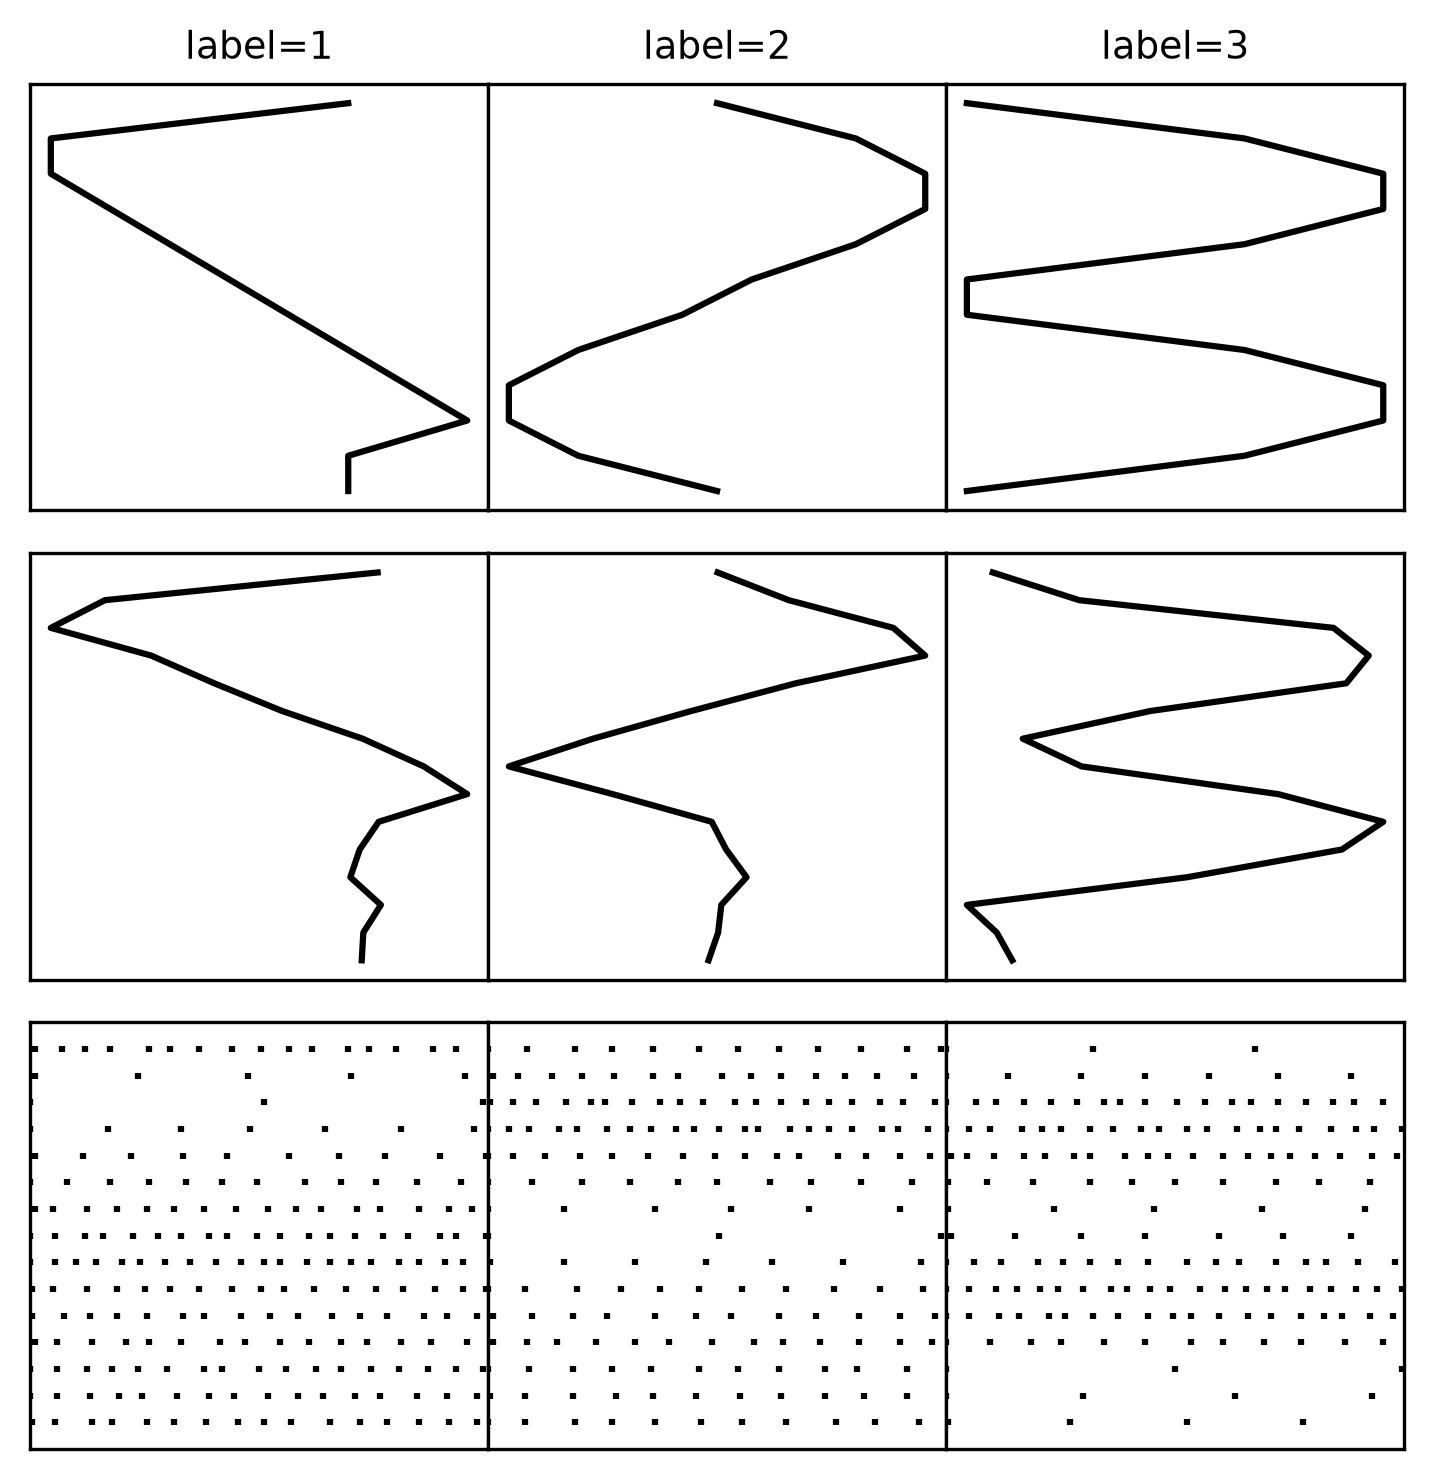

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import sys
import os
# Add the sibling 'scripts' directory to the path so we can import plotting_utils
scripts_path = os.path.abspath('../scripts')
if scripts_path not in sys.path:
    sys.path.append(scripts_path)
import plotting_utils as pu

def plot_mnist1d_comparison(dataset, digits_to_plot=None, ratio=1.0, snippet_T=1000, dark_mode=False):
    """
    Plots a 3-row grid for the MNIST1D dataset, showing specified digits in order:
    Row 1: Clean template (no noise/padding)
    Row 2: Transformed pattern (with noise/padding, before spike encoding)
    Row 3: Snippet of the corresponding raster plot
    """
    if digits_to_plot is None:
        digits_to_plot = list(range(10))
        
    rows = 3
    cols = len(digits_to_plot)
    
    # 1. Apply latexify to standardize font families, sizes, and paper layout
    pu.latexify(width_fraction=1.0, base_font_size=9)
    
    # 2. Use subplots instead of a hardcoded figsize/dpi, adjusting spacing directly
    fig, axes = plt.subplots(rows, cols, gridspec_kw={'wspace': 0, 'hspace': 0.1})
    templates = get_templates()
    
    # Find the first index in the dataset for each requested digit
    digit_indices = []
    labels_array = np.array(dataset.labels)
    for digit in digits_to_plot:
        idx = np.where(labels_array == digit)[0][0]
        digit_indices.append(idx)
    
    # Colors matching plotting_utils.py style
    bg_color = 'k' if dark_mode else 'w'
    fg_color = 'w' if dark_mode else 'k'
    
    for plot_col, ix in enumerate(digit_indices):
        x_spikes, _, label, _, _ = dataset[ix]
        label_int = int(label)
        
        if hasattr(dataset, 'raw_x'):
            transformed_x = dataset.raw_x[ix]
        else:
            T = x_spikes.shape[0]
            transformed_x = x_spikes.sum(axis=0) * (1000 / T)
            
        num_features = len(transformed_x)
        
        # ==========================================
        # ROW 1: Clean Template
        # ==========================================
        ax1 = axes[0, plot_col]
        clean_x = templates['x'][label_int]
        t_clean = np.arange(len(clean_x))
        clean_x = clean_x - np.mean(clean_x)
        
        # 3. Scaled down linewidths for paper printing
        ax1.plot(clean_x, t_clean, color=fg_color, linestyle='-', linewidth=1.5)
        if dark_mode:
            ax1.set_facecolor(bg_color)
            
        # 4. Removed hardcoded fontsize=22
        ax1.set_title(f"label={label_int}")
        ax1.invert_yaxis()
        ax1.set_xticks([])
        ax1.set_yticks([])
        
        # ==========================================
        # ROW 2: Transformed Pattern
        # ==========================================
        ax2 = axes[1, plot_col]
        t_spatial = np.arange(num_features)
        transformed_x = transformed_x - np.mean(transformed_x)
        
        ax2.plot(transformed_x, t_spatial, color=fg_color, linestyle='-', linewidth=1.5)
        if dark_mode:
            ax2.set_facecolor(bg_color)
            
        ax2.invert_yaxis()
        ax2.set_xticks([])
        ax2.set_yticks([])
        
        # ==========================================
        # ROW 3: Raster Plot Snippet
        # ==========================================
        ax3 = axes[2, plot_col]
        snippet = x_spikes[:snippet_T, :]
        times, neurons = np.where(snippet > 0)
        
        # 5. Scaled down marker sizes (s=8 -> s=2)
        ax3.scatter(times, neurons, s=2, c=fg_color, marker='|')
        if dark_mode:
            ax3.set_facecolor(bg_color)
            
        ax3.set_xlim(0, snippet_T)
        ax3.set_ylim(-1, num_features)
        
        ax3.invert_yaxis()
        ax3.set_xticks([])
        ax3.set_yticks([])
        
    return fig

plot_mnist1d_comparison(spiking_dataset, digits_to_plot=[1, 2, 3], snippet_T=200, dark_mode=False);


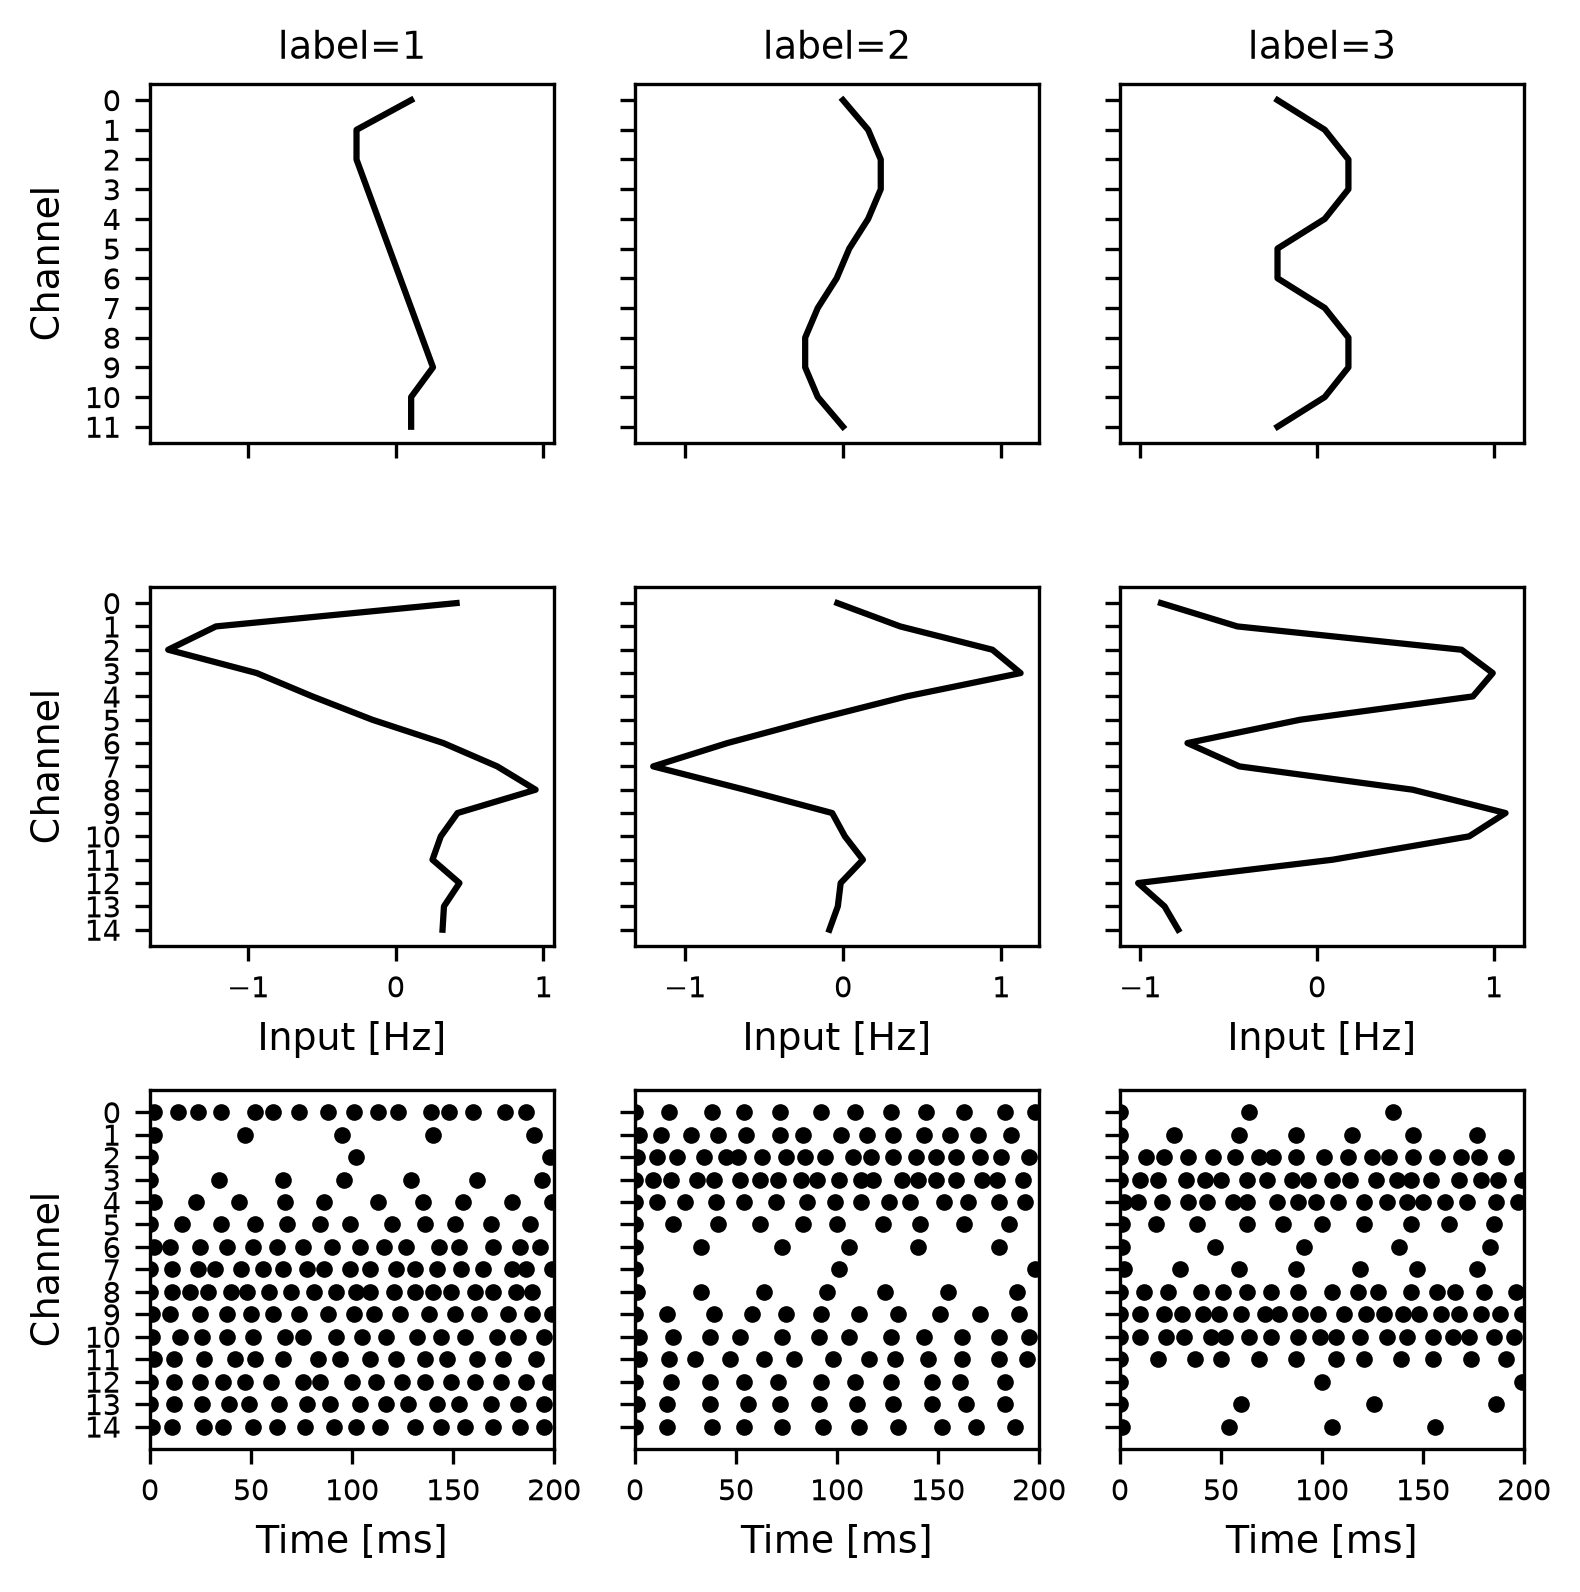

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import sys
import os

# Add the sibling 'scripts' directory to the path so we can import plotting_utils
scripts_path = os.path.abspath('../scripts')
if scripts_path not in sys.path:
    sys.path.append(scripts_path)

import plotting_utils as pu

def plot_mnist1d_comparison(dataset, digits_to_plot=None, ratio=1.0, snippet_T=1000, dark_mode=False):
    """
    Plots a 3-row grid for the MNIST1D dataset.
    Row 1: Clean template
    Row 2: Transformed pattern (Input Hz)
    Row 3: Raster plot (Time ms)
    """
    if digits_to_plot is None:
        digits_to_plot = list(range(10))
        
    rows = 3
    cols = len(digits_to_plot)
    
    # 1. Standardize font size and styles
    pu.latexify(width_fraction=1.0, base_font_size=9)
    
    # 2. Add wspace and hspace to disconnect the plots
    # sharey='row' ensures the Y axes are perfectly aligned across all columns
    fig, axes = plt.subplots(rows, cols, sharey='row', gridspec_kw={'wspace': 0.2, 'hspace': 0.4})
    
    templates = get_templates()
    
    # Find the first index in the dataset for each requested digit
    digit_indices = []
    labels_array = np.array(dataset.labels)
    for digit in digits_to_plot:
        idx = np.where(labels_array == digit)[0][0]
        digit_indices.append(idx)
    
    bg_color = 'k' if dark_mode else 'w'
    fg_color = 'w' if dark_mode else 'k'
    
    for plot_col, ix in enumerate(digit_indices):
        x_spikes, _, label, _, _ = dataset[ix]
        label_int = int(label)
        
        if hasattr(dataset, 'raw_x'):
            transformed_x = dataset.raw_x[ix]
        else:
            T = x_spikes.shape[0]
            transformed_x = x_spikes.sum(axis=0) * (1000 / T)
            
        num_features = len(transformed_x)
        
        # ==========================================
        # ROW 1: Clean Template
        # ==========================================
        ax1 = axes[0, plot_col]
        clean_x = templates['x'][label_int]
        t_clean = np.arange(len(clean_x))
        clean_x = clean_x - np.mean(clean_x)
        
        ax1.plot(clean_x, t_clean, color=fg_color, linestyle='-', linewidth=1.5)
        if dark_mode: 
            ax1.set_facecolor(bg_color)
            
        ax1.set_title(f"label={label_int}")
        ax1.invert_yaxis()
        
        # Marker for every channel
        ax1.set_yticks(t_clean)
        
        # Y-axis label only on the far left column
        if plot_col == 0:
            ax1.set_ylabel("Channel")
            
        # ==========================================
        # ROW 2: Transformed Pattern
        # ==========================================
        ax2 = axes[1, plot_col]
        t_spatial = np.arange(num_features)
        transformed_x = transformed_x - np.mean(transformed_x)
        
        ax2.plot(transformed_x, t_spatial, color=fg_color, linestyle='-', linewidth=1.5)
        if dark_mode: 
            ax2.set_facecolor(bg_color)
            
        ax2.invert_yaxis()
        
        # Marker for every channel
        ax2.set_yticks(t_spatial)
        
        if plot_col == 0:
            ax2.set_ylabel("Channel")
            
        # X-axis label
        ax2.set_xlabel("Input [Hz]")
        
        # Share X axis between Row 1 and Row 2, and hide Row 1's tick labels
        ax1.sharex(ax2)
        ax1.tick_params(labelbottom=False)
        
        # ==========================================
        # ROW 3: Raster Plot Snippet
        # ==========================================
        ax3 = axes[2, plot_col]
        snippet = x_spikes[:snippet_T, :]
        times, neurons = np.where(snippet > 0)
        
        # Matching scatter style to plot_predictions
        ax3.scatter(times, neurons, s=16, linewidths=0, c=fg_color)
        if dark_mode: 
            ax3.set_facecolor(bg_color)
            
        ax3.set_xlim(0, snippet_T)
        ax3.set_ylim(-1, num_features)
        ax3.invert_yaxis()
        
        # Marker for every channel
        ax3.set_yticks(t_spatial)
        
        if plot_col == 0:
            ax3.set_ylabel("Channel")
            
        # X-axis label
        ax3.set_xlabel("Time [ms]")
        
    return fig

plot_mnist1d_comparison(spiking_dataset, digits_to_plot=[1, 2, 3], snippet_T=200, dark_mode=False);

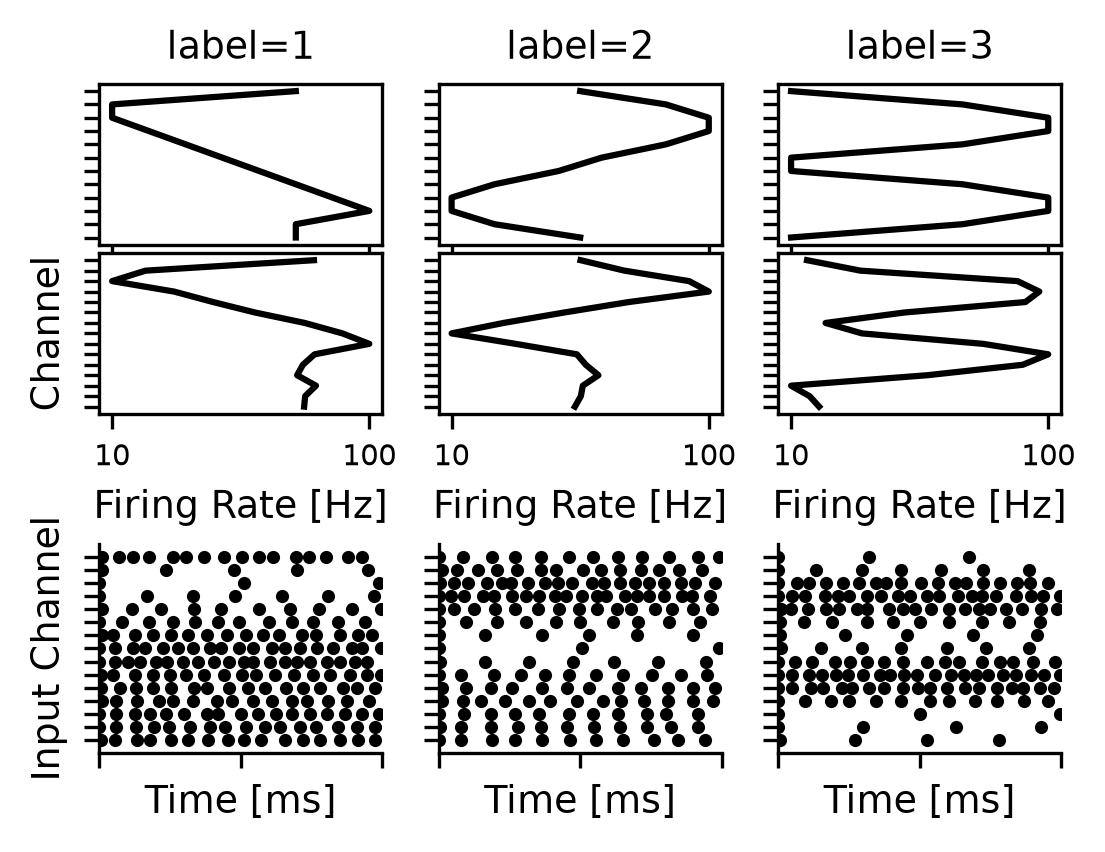

In [34]:
from mpl_toolkits.mplot3d import axes3d
from mpl_toolkits.mplot3d import axes3d
from mpl_toolkits.mplot3d import axes3d
from mpl_toolkits.mplot3d import axes3d
from mpl_toolkits.mplot3d import axes3d
import matplotlib.pyplot as plt
import numpy as np
import sys
import os

# Add the sibling 'scripts' directory to the path so we can import plotting_utils
scripts_path = os.path.abspath('../scripts')
if scripts_path not in sys.path:
    sys.path.append(scripts_path)

import plotting_utils as pu

def plot_mnist1d_comparison(dataset, digits_to_plot=None, ratio=1.0, snippet_T=1000, dark_mode=False):
    """
    Plots a 3-row grid for the MNIST1D dataset.
    Row 1: Clean template
    Row 2: Transformed pattern (Input Hz)
    Row 3: Raster plot (Time ms)
    """
    if digits_to_plot is None:
        digits_to_plot = list(range(10))
        
    cols = len(digits_to_plot)
    
    # 1. Standardize font size and styles
    pu.latexify(width_fraction=0.7, height_ratio=0.7, base_font_size=9)
    
    # 2. Use nested GridSpecs to decrease gap between Row 1 & 2, while preserving space before Row 3
    fig = plt.figure()
    gs_top = fig.add_gridspec(2, cols, bottom=0.5, hspace=0.05, wspace=0.2)
    gs_bot = fig.add_gridspec(1, cols, top=0.35, wspace=0.2)
    
    axes = np.empty((3, cols), dtype=object)
    for c in range(cols):
        axes[0, c] = fig.add_subplot(gs_top[0, c])
        axes[1, c] = fig.add_subplot(gs_top[1, c])
        axes[2, c] = fig.add_subplot(gs_bot[0, c])
        
        # Share Y-axis within each row
        if c > 0:
            axes[0, c].sharey(axes[0, 0])
            axes[1, c].sharey(axes[1, 0])
            axes[2, c].sharey(axes[2, 0])
            
        # Ensure that the X-axis limits for Row 1 & 2 are shared across ALL columns globally
        axes[0, c].sharex(axes[0, 0])
        axes[1, c].sharex(axes[0, 0])
    
    templates = get_templates() # Ensure this is defined in your notebook
    
    # Find the first index in the dataset for each requested digit
    digit_indices = []
    labels_array = np.array(dataset.labels)
    for digit in digits_to_plot:
        idx = np.where(labels_array == digit)[0][0]
        digit_indices.append(idx)
    
    bg_color = 'k' if dark_mode else 'w'
    fg_color = 'w' if dark_mode else 'k'
    
    # Get the dataset's native firing rate limits (defaults to 10 and 100 if attributes are missing)
    fmin = getattr(dataset, 'fmin', 10)
    fmax = getattr(dataset, 'fmax', 100)
    
    for plot_col, ix in enumerate(digit_indices):
        x_spikes, _, label, _, _ = dataset[ix]
        label_int = int(label)
        
        if hasattr(dataset, 'raw_x'):
            # Fetch the raw sequence and min-max scale it to [fmin, fmax] EXACTLY like the dataset does
            seq = dataset.raw_x[ix]
            s_min, s_max = seq.min(), seq.max()
            norm_seq = (seq - s_min) / (s_max - s_min) if (s_max - s_min > 1e-6) else np.zeros_like(seq)
            transformed_x = fmin + (fmax - fmin) * norm_seq
        else:
            # Fallback to empirical average spike rate if raw_x is not saved
            T = x_spikes.shape[0]
            transformed_x = x_spikes.sum(axis=0) * (1000 / T)
            
        num_features = len(transformed_x)
        
        # ==========================================
        # ROW 1: Clean Template
        # ==========================================
        ax1 = axes[0, plot_col]
        clean_x = templates['x'][label_int]
        t_clean = np.arange(len(clean_x))
        
        # Map clean template identically into the [fmin, fmax] firing rate space
        c_min, c_max = clean_x.min(), clean_x.max()
        norm_clean = (clean_x - c_min) / (c_max - c_min) if (c_max - c_min > 1e-6) else np.zeros_like(clean_x)
        clean_x = fmin + (fmax - fmin) * norm_clean
        
        ax1.plot(clean_x, t_clean, color=fg_color, linestyle='-', linewidth=1.5)
        if dark_mode: 
            ax1.set_facecolor(bg_color)
            
        ax1.set_title(f"label={label_int}")
        ax1.invert_yaxis()
        
        # Mark every single channel, but remove labels
        ax1.set_yticks(t_clean)
        ax1.tick_params(labelleft=False, labelbottom=False)
        
        # Bring "Channel" label back for the far left column
        # if plot_col == 0:
        #     ax1.set_ylabel("Input Channel")
        
        # ==========================================
        # ROW 2: Transformed Pattern
        # ==========================================
        ax2 = axes[1, plot_col]
        t_spatial = np.arange(num_features)
        
        # Plot transformed pattern in actual Hz
        ax2.plot(transformed_x, t_spatial, color=fg_color, linestyle='-', linewidth=1.5)
        if dark_mode: 
            ax2.set_facecolor(bg_color)
            
        ax2.invert_yaxis()
        
        # Mark every single channel, but remove labels
        ax2.set_yticks(t_spatial)
        ax2.tick_params(labelleft=False)
        
        # Bring "Channel" label back for the far left column
        if plot_col == 0:
            ax2.set_ylabel("Channel")
            
        ax2.set_xlabel("Firing Rate [Hz]")
        
        # Explicitly mark ONLY fmin and fmax on the X-axis for Row 2 
        # (This applies to Row 1 as well since they share the X-axis)
        ax2.set_xticks([fmin, fmax])
        
        # ==========================================
        # ROW 3: Raster Plot Snippet
        # ==========================================
        ax3 = axes[2, plot_col]
        snippet = x_spikes[:snippet_T, :]
        times, neurons = np.where(snippet > 0)
        
        # Even smaller scatter dots (s=4)
        ax3.scatter(times, neurons, s=10, linewidths=0, c=fg_color)
        if dark_mode: 
            ax3.set_facecolor(bg_color)
            
        ax3.set_xlim(0, snippet_T)
        ax3.set_ylim(-1, num_features)
        ax3.invert_yaxis()
        
        # Mark every single channel, remove Y-labels. Remove X-tick numbers but keep the "Time [ms]" label.
        ax3.set_yticks(t_spatial)
        ax3.tick_params(labelleft=False, labelbottom=False)
        
        # Bring "Channel" label back for the far left column
        if plot_col == 0:
            ax3.set_ylabel("Input Channel")
            
        ax3.set_xlabel("Time [ms]")
        
        ax3.spines['top'].set_visible(False)
        ax3.spines['right'].set_visible(False)
        
    return fig

plot_mnist1d_comparison(spiking_dataset, digits_to_plot=[1, 2, 3], snippet_T=200, dark_mode=False);

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import sys
import os
import torch
import torchvision

# Add the sibling 'scripts' directory to the path so we can import plotting_utils
scripts_path = os.path.abspath('../scripts')
if scripts_path not in sys.path:
    sys.path.append(scripts_path)

import plotting_utils as pu

def plot_mnist1d_comparison(dataset, digits_to_plot=None, ratio=1.0, snippet_T=1000, dark_mode=False, top_row='clean'):
    """
    Plots a 3-row grid for the MNIST1D dataset.
    Row 1: Clean 1D template OR Classic 2D MNIST Image
    Row 2: Empirical Transformed pattern (Input Hz)
    Row 3: Raster plot (Time ms)
    
    top_row: 'clean' (default) plots the 12-dim length 1D template.
             'classic' plots a 28x28 classic MNIST image of the same digit.
    """
    if digits_to_plot is None:
        digits_to_plot = list(range(10))
        
    cols = len(digits_to_plot)
    
    # Standardize font size and styles
    pu.latexify(width_fraction=0.7, height_ratio=0.8, base_font_size=9)
    
    # 2. Use nested GridSpecs to decrease gap between Row 1 & 2, while preserving space before Row 3
    fig = plt.figure()
    gs_top = fig.add_gridspec(2, cols, bottom=0.5, hspace=0.1, wspace=0.2)
    gs_bot = fig.add_gridspec(1, cols, top=0.35, wspace=0.2)
    
    axes = np.empty((3, cols), dtype=object)
    for c in range(cols):
        axes[0, c] = fig.add_subplot(gs_top[0, c])
        axes[1, c] = fig.add_subplot(gs_top[1, c])
        axes[2, c] = fig.add_subplot(gs_bot[0, c])
        
        # Share Y-axis within each row
        if c > 0:
            axes[0, c].sharey(axes[0, 0])
            axes[1, c].sharey(axes[1, 0])
            axes[2, c].sharey(axes[2, 0])
            
        # Share X-axis limits
        if top_row == 'clean':
            # Row 1 (1D) and Row 2 share X globally
            axes[0, c].sharex(axes[0, 0])
            axes[1, c].sharex(axes[0, 0])
        else:
            # Row 1 is a 2D image and cannot share X with Row 2. 
            # Row 2 shares X globally with itself.
            axes[0, c].sharex(axes[0, 0])
            axes[1, c].sharex(axes[1, 0])
    
    # Prepare data for Row 1
    if top_row == 'clean':
        templates = get_templates()
    else:
        # Load classic MNIST once if requested
        classic_mnist = torchvision.datasets.MNIST(root='./data', train=True, download=True)
    
    digit_indices = []
    labels_array = np.array(dataset.labels)
    for digit in digits_to_plot:
        idx = np.where(labels_array == digit)[0][0]
        digit_indices.append(idx)
    
    bg_color = 'k' if dark_mode else 'w'
    fg_color = 'w' if dark_mode else 'k'
    
    # Get dataset's native firing rate limits (defaults to 10 and 100)
    fmin = getattr(dataset, 'fmin', 10)
    fmax = getattr(dataset, 'fmax', 100)
    
    for plot_col, ix in enumerate(digit_indices):
        x_spikes, _, label, _, _ = dataset[ix]
        label_int = int(label)
        
        # Row 2 is ALWAYS the empirical firing rate calculated from the spikes
        T = x_spikes.shape[0]
        empirical_hz = x_spikes.sum(axis=0) * (1000 / T)
        num_features = len(empirical_hz)
        
        # ==========================================
        # ROW 1: Clean Template OR Classic 2D MNIST
        # ==========================================
        ax1 = axes[0, plot_col]
        
        if top_row == 'clean':
            raw_top_x = templates['x'][label_int]
            t_top = np.arange(len(raw_top_x))
            
            # Map Row 1 identically into the [fmin, fmax] firing rate space
            c_min, c_max = raw_top_x.min(), raw_top_x.max()
            norm_top = (raw_top_x - c_min) / (c_max - c_min) if (c_max - c_min > 1e-6) else np.zeros_like(raw_top_x)
            top_x = fmin + (fmax - fmin) * norm_top
            
            ax1.plot(top_x, t_top, color=fg_color, linestyle='-', linewidth=1.5)
            if dark_mode: ax1.set_facecolor(bg_color)
            ax1.invert_yaxis()
            ax1.set_yticks(t_top)
            ax1.tick_params(labelleft=False, labelbottom=False)
            if plot_col == 0:
                ax1.set_ylabel("Channel")
                
        elif top_row == 'classic':
            # Grab the first classic 2D MNIST image corresponding to this digit
            classic_idx = (classic_mnist.targets == label_int).nonzero(as_tuple=True)[0][0]
            img = classic_mnist.data[classic_idx].numpy()
            
            cmap = 'gray'
            ax1.imshow(img, cmap=cmap, aspect='auto')
            ax1.axis('off')  # Hide all axes/ticks for the 2D image
            
        ax1.set_title(f"label={label_int}")
        
        # ==========================================
        # ROW 2: Transformed Pattern (Empirical Hz)
        # ==========================================
        ax2 = axes[1, plot_col]
        t_spatial = np.arange(num_features)
        
        ax2.plot(empirical_hz, t_spatial, color=fg_color, linestyle='-', linewidth=1.5)
        if dark_mode: 
            ax2.set_facecolor(bg_color)
            
        ax2.invert_yaxis()
        
        ax2.set_yticks(t_spatial)
        ax2.tick_params(labelleft=False)
        if plot_col == 0:
            ax2.set_ylabel("Channel")
            
        ax2.set_xlabel("Firing Rate [Hz]")
        ax2.set_xticks([fmin, fmax])
        ax2.set_xlim(-40, 150)

        
        # ==========================================
        # ROW 3: Raster Plot Snippet
        # ==========================================
        ax3 = axes[2, plot_col]
        snippet = x_spikes[:snippet_T, :]
        times, neurons = np.where(snippet > 0)
        
        ax3.scatter(times, neurons, s=9, linewidths=0, c=fg_color)
        if dark_mode: 
            ax3.set_facecolor(bg_color)
            
        ax3.set_xlim(0, snippet_T)
        ax3.set_ylim(-1, num_features)
        ax3.invert_yaxis()
        
        ax3.set_yticks(t_spatial)
        ax3.tick_params(labelleft=False, labelbottom=False)
        if plot_col == 0:
            ax3.set_ylabel("Channel")
            
        ax3.set_xlabel("Time [ms]")
        ax3.spines['top'].set_visible(False)
        ax3.spines['right'].set_visible(False)
        
    return fig



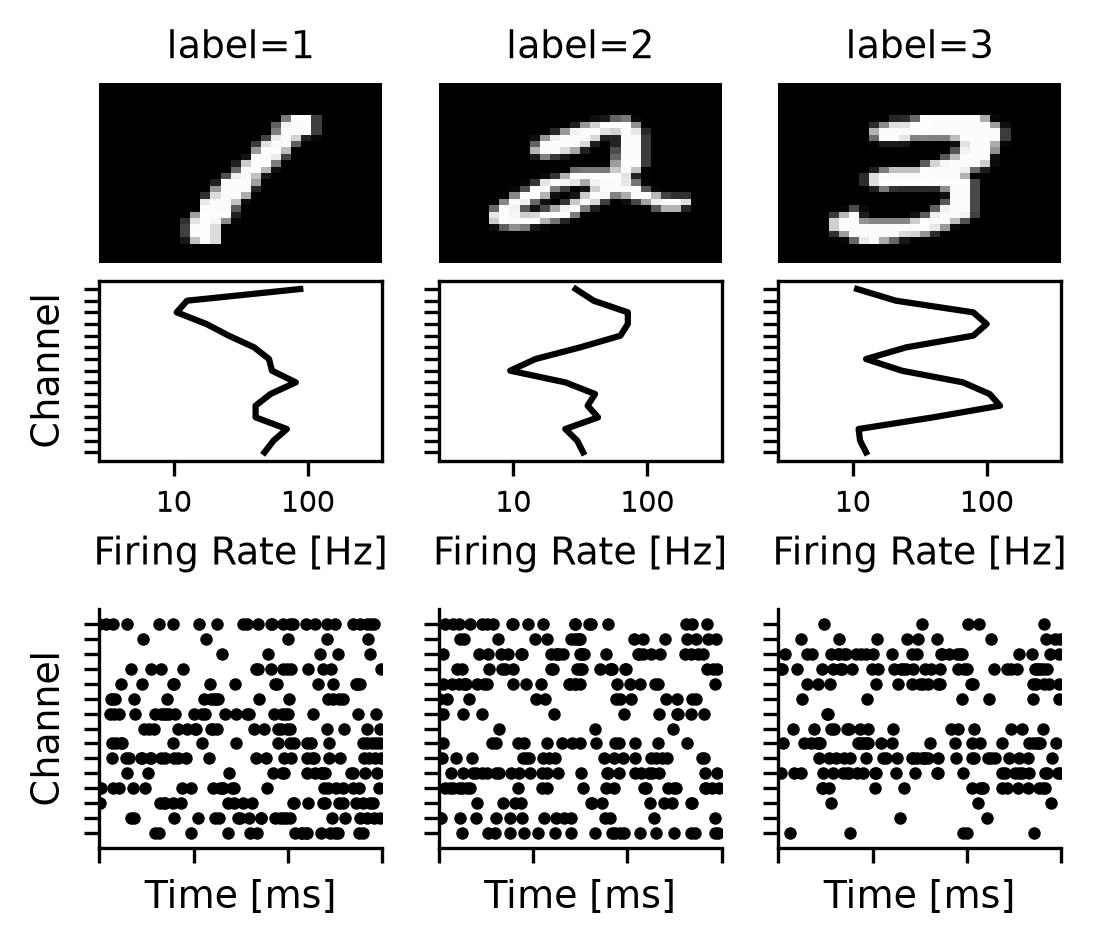

In [38]:
plot_mnist1d_comparison(spiking_dataset, digits_to_plot=[1, 2, 3], snippet_T=300, dark_mode=False, top_row='classic');
